# 第 1 步：失焦与噪声

只做光学成像，不进行 AI 复原。你的实验前预测是：**边缘条纹更加模糊**。

每次只改一个参数，然后重新运行参数格及后面的格子。实际观察写入 `PARTICIPATION.md`。

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    raise RuntimeError('请从项目根目录运行这个 Notebook')
sys.path.insert(0, str(ROOT))
from IPython.display import Image, display
from learn_optics import run_experiment
print('项目路径:', ROOT)

项目路径: /Users/chenruidong/Desktop/AI光学项目


## 你修改这一格

实验 A：保持 `NOISE_SIGMA = 0.01`，依次尝试失焦 `0.0`、`0.15`、`0.30`。

实验 B：保持 `DEFOCUS_WAVES = 0.15`，依次尝试噪声 `0.0`、`0.01`、`0.03`。`SEED` 固定，保证比较使用同一个底层随机样本。

In [2]:
DEFOCUS_WAVES = 0.15
NOISE_SIGMA = 0.01
SEED = 42

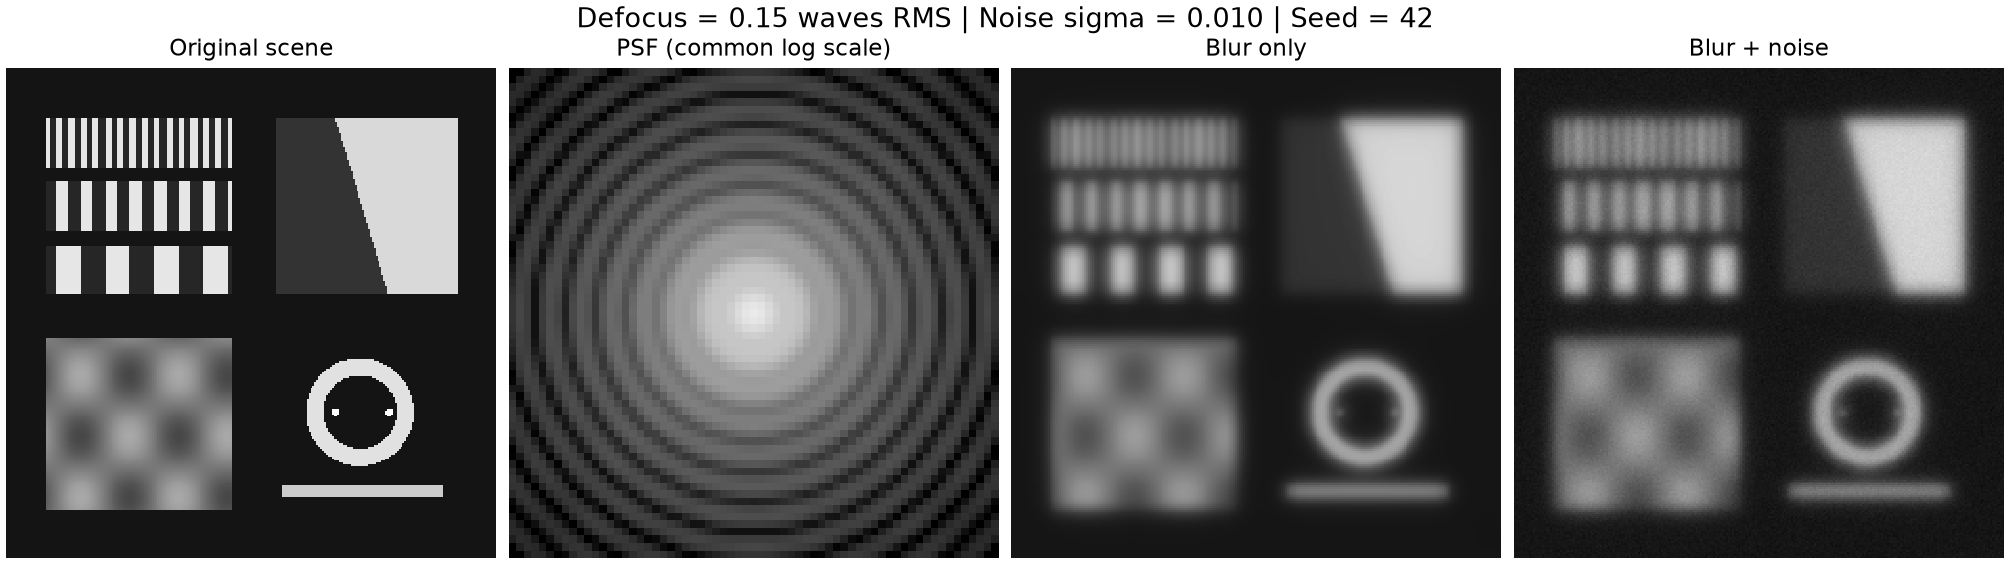

In [3]:
result = run_experiment(DEFOCUS_WAVES, NOISE_SIGMA, SEED)
display(Image(filename=str(ROOT / 'results/learning/current_comparison.png')))

四个面板依次是原图、光斑 PSF、仅模糊、模糊加噪。PSF 使用固定对数灰度以显示较暗的结构；场景图均使用固定 `[0,1]` 显示范围。

观察细条纹的明暗差、斜边过渡和左下方平滑区域。零失焦仍存在有限孔径衍射。

In [4]:
print('PSF 总和:', result['psf'].sum())
print('截取区域保留的离散光能比例:', result['metadata']['crop_energy_fraction'])
print('像面采样间距:', result['metadata']['q_step'], 'lambda*f/D')
print('原始观测范围:', result['noisy'].min(), result['noisy'].max())
print('是否截断过观测:', result['metadata']['observation_clipped'])

PSF 总和: 1.0
截取区域保留的离散光能比例: 0.9886393523972381
像面采样间距: 0.25 lambda*f/D
原始观测范围: 0.041910561249972486 0.8715419241152483
是否截断过观测: False


## 完成本步前，写下自己的观察

1. 失焦增大后，你实际看到哪处细节变化？
2. 只改噪声时，PSF 是否变化？
3. 这与你的预测是否一致？

这些答案需要你填写。学习参数不自动成为正式实验参数；当前图片也不是 AI 复原结果。